<h1><center> Project: Daily Minimum Temperatures in Melbourne


<hr>

In [170]:
import pandas as pd

import matplotlib.pyplot as plt

In [171]:
# Load and read data

df = pd.read_csv('/content/data.csv', parse_dates= [0])
df.head()

,Date,"Daily minimum temperatures in Melbourne, Australia, 1981-1990"
0,1981-01-01,20.7
1,1981-01-02,17.9
2,1981-01-03,18.8
3,1981-01-04,14.6
4,1981-01-05,15.8


In [172]:
df.dtypes

,0
Date,datetime64[ns]
"Daily minimum temperatures in Melbourne, Australia, 1981-1990",object


In [173]:
# Rename column 'Daily minimum temperatures in Melbourne, Australia, 1981-1990' to 'Temperature' pour la simplicité

df = df.rename(columns= {'Daily minimum temperatures in Melbourne, Australia, 1981-1990': 'Temperature'})

df.columns

Index(['Date', 'Temperature'], dtype='object')

In [174]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3650 entries, 0 to 3649
Data columns (total 2 columns):
 #   Column       Non-Null Count  Dtype         
---  ------       --------------  -----         
 0   Date         3650 non-null   datetime64[ns]
 1   Temperature  3650 non-null   object        
dtypes: datetime64[ns](1), object(1)
memory usage: 57.2+ KB


In [175]:
df.shape  # 10 ans --> 365*10= 3650 DONNEES

(3650, 2)

In [176]:
df.dtypes

,0
Date,datetime64[ns]
Temperature,object


In [177]:
df.isnull().sum()

,0
Date,0
Temperature,0


In [178]:
df["Temperature"].unique()

array(['20.7', '17.9', '18.8', '14.6', '15.8', '17.4', '21.8', '20.0',
       '16.2', '13.3', '16.7', '21.5', '25.0', '20.6', '24.8', '17.7',
       '15.5', '18.2', '12.1', '14.4', '16.0', '16.5', '18.7', '19.4',
       '17.2', '15.1', '15.4', '15.3', '21.9', '19.9', '16.6', '16.8',
       '17.1', '15.0', '13.7', '13.9', '18.3', '22.0', '22.1', '21.2',
       '18.4', '16.1', '15.7', '18.5', '16.9', '17.5', '17.8', '18.6',
       '17.0', '14.3', '11.4', '16.3', '11.8', '12.2', '14.7', '11.3',
       '10.6', '11.7', '14.2', '11.2', '8.1', '8.0', '8.8', '13.4',
       '10.9', '11.0', '14.5', '18.1', '10.0', '14.9', '15.9', '13.0',
       '7.6', '11.5', '13.5', '12.4', '13.2', '13.8', '9.0', '9.8', '8.9',
       '7.4', '9.9', '9.3', '8.6', '11.9', '14.0', '12.0', '10.5', '10.7',
       '10.1', '5.3', '6.6', '8.5', '5.9', '3.2', '2.1', '3.4', '5.4',
       '9.6', '12.3', '12.6', '12.8', '11.6', '5.7', '7.1', '2.5', '3.5',
       '4.6', '7.7', '10.4', '9.2', '6.1', '2.7', '4.3', '6.3', '3.8'

In [179]:
# Corriger les données de temperature en remplaçant ? par ""

df["Temperature"] = df["Temperature"].str.replace('?', '', regex= False)
df["Temperature"].unique()

array(['20.7', '17.9', '18.8', '14.6', '15.8', '17.4', '21.8', '20.0',
       '16.2', '13.3', '16.7', '21.5', '25.0', '20.6', '24.8', '17.7',
       '15.5', '18.2', '12.1', '14.4', '16.0', '16.5', '18.7', '19.4',
       '17.2', '15.1', '15.4', '15.3', '21.9', '19.9', '16.6', '16.8',
       '17.1', '15.0', '13.7', '13.9', '18.3', '22.0', '22.1', '21.2',
       '18.4', '16.1', '15.7', '18.5', '16.9', '17.5', '17.8', '18.6',
       '17.0', '14.3', '11.4', '16.3', '11.8', '12.2', '14.7', '11.3',
       '10.6', '11.7', '14.2', '11.2', '8.1', '8.0', '8.8', '13.4',
       '10.9', '11.0', '14.5', '18.1', '10.0', '14.9', '15.9', '13.0',
       '7.6', '11.5', '13.5', '12.4', '13.2', '13.8', '9.0', '9.8', '8.9',
       '7.4', '9.9', '9.3', '8.6', '11.9', '14.0', '12.0', '10.5', '10.7',
       '10.1', '5.3', '6.6', '8.5', '5.9', '3.2', '2.1', '3.4', '5.4',
       '9.6', '12.3', '12.6', '12.8', '11.6', '5.7', '7.1', '2.5', '3.5',
       '4.6', '7.7', '10.4', '9.2', '6.1', '2.7', '4.3', '6.3', '3.8'

In [180]:
# convertir la colonne en nombre

df["Temperature"] = pd.to_numeric(df["Temperature"], errors= 'coerce')  # convertir les valeurs non numériques en NaN

df["Temperature"].unique()

array([20.7, 17.9, 18.8, 14.6, 15.8, 17.4, 21.8, 20. , 16.2, 13.3, 16.7,
       21.5, 25. , 20.6, 24.8, 17.7, 15.5, 18.2, 12.1, 14.4, 16. , 16.5,
       18.7, 19.4, 17.2, 15.1, 15.4, 15.3, 21.9, 19.9, 16.6, 16.8, 17.1,
       15. , 13.7, 13.9, 18.3, 22. , 22.1, 21.2, 18.4, 16.1, 15.7, 18.5,
       16.9, 17.5, 17.8, 18.6, 17. , 14.3, 11.4, 16.3, 11.8, 12.2, 14.7,
       11.3, 10.6, 11.7, 14.2, 11.2,  8.1,  8. ,  8.8, 13.4, 10.9, 11. ,
       14.5, 18.1, 10. , 14.9, 15.9, 13. ,  7.6, 11.5, 13.5, 12.4, 13.2,
       13.8,  9. ,  9.8,  8.9,  7.4,  9.9,  9.3,  8.6, 11.9, 14. , 12. ,
       10.5, 10.7, 10.1,  5.3,  6.6,  8.5,  5.9,  3.2,  2.1,  3.4,  5.4,
        9.6, 12.3, 12.6, 12.8, 11.6,  5.7,  7.1,  2.5,  3.5,  4.6,  7.7,
       10.4,  9.2,  6.1,  2.7,  4.3,  6.3,  3.8,  4.4,  4.8,  5.8,  6.2,
        7.3, 10.2,  9.5,  6.5,  7. ,  8.3,  6.8,  7.2,  5. ,  6.9,  5.2,
        3. ,  5.6,  7.9, 10.3,  9.7, 12.5,  3.9,  6. ,  5.5,  7.5,  7.8,
       14.1, 12.9,  9.1,  8.4, 13.6,  9.4, 14.8, 16

In [181]:
df.describe()

,Date,Temperature
count,3650,3650.000000
mean,1985-12-31 07:12:00,11.177753
min,1981-01-01 00:00:00,0.000000
25%,1983-07-02 06:00:00,8.300000
50%,1985-12-31 12:00:00,11.000000
75%,1988-06-30 18:00:00,14.000000
max,1990-12-31 00:00:00,26.300000
std,NaN,4.071837


In [182]:
num_years = df['Date'].dt.year.nunique()
years = df["Date"].dt.year.unique()

print(f" Les données ont été stockées pendant {num_years} années: \n {years}")

 Les données ont été stockées pendant 10 années: 
 [1981 1982 1983 1984 1985 1986 1987 1988 1989 1990]


In [183]:
df.set_index('Date', inplace= True) # Définir la colonne 'Date' comme index du Dataframe

In [184]:
df.head()

,Temperature
Date,
1981-01-01,20.7
1981-01-02,17.9
1981-01-03,18.8
1981-01-04,14.6
1981-01-05,15.8


In [185]:
df_ml = df.copy() # pour la partie machine learning

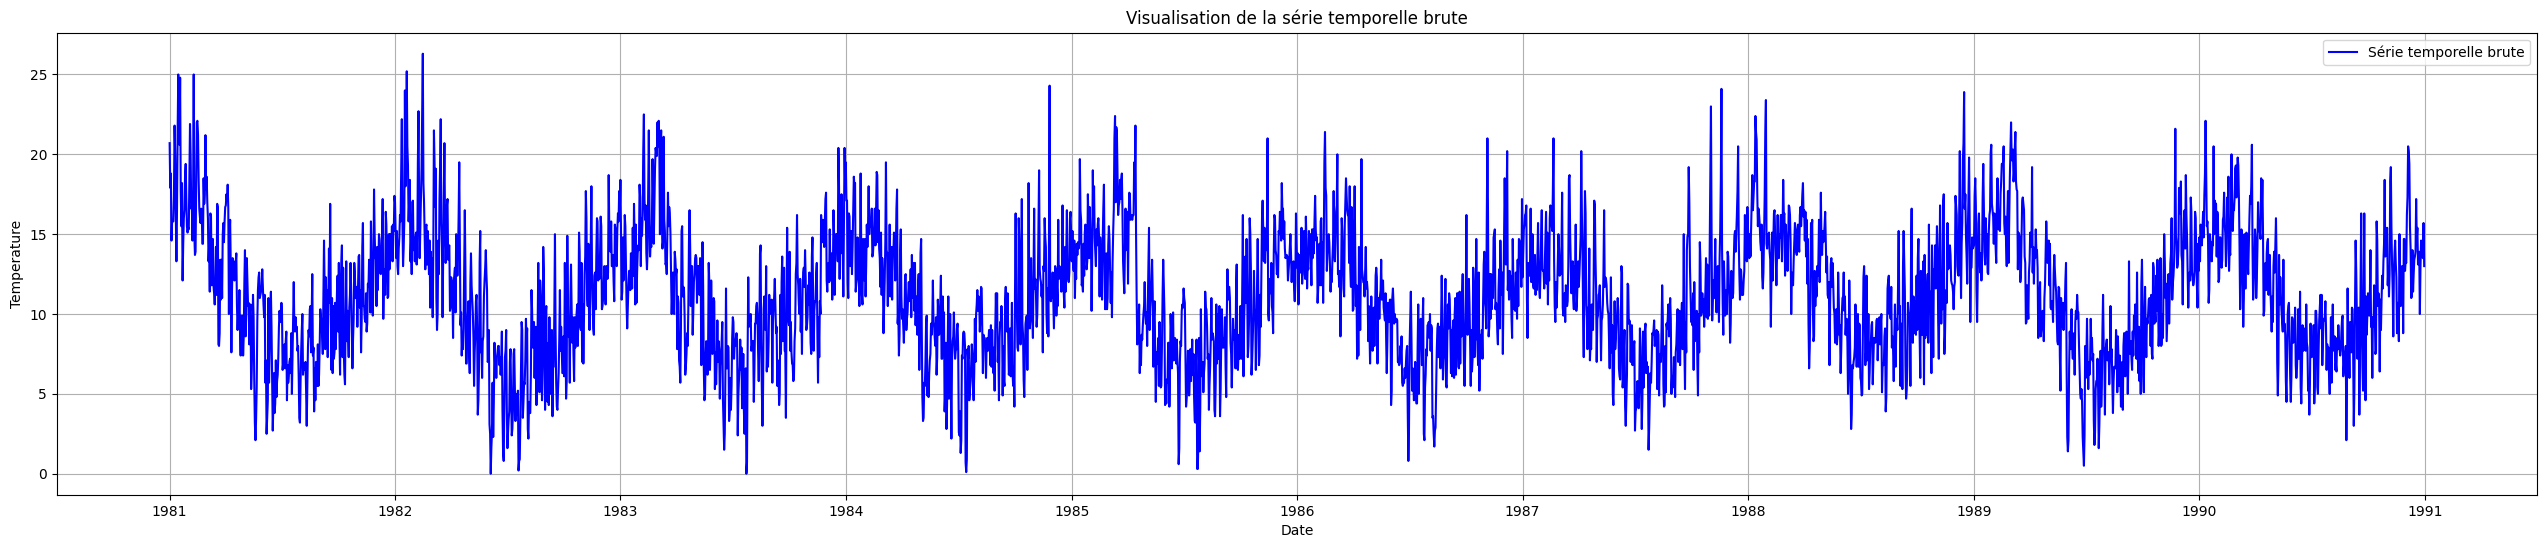

In [186]:
# Plot the entire serie
plt.figure(figsize=(32,6))

plt.plot(df.index, df['Temperature'], label= "Série temporelle brute", color= "blue")

plt.title("Visualisation de la série temporelle brute")
plt.xlabel("Date")

plt.ylabel("Temperature")
plt.grid(True)
plt.legend()
plt.show()

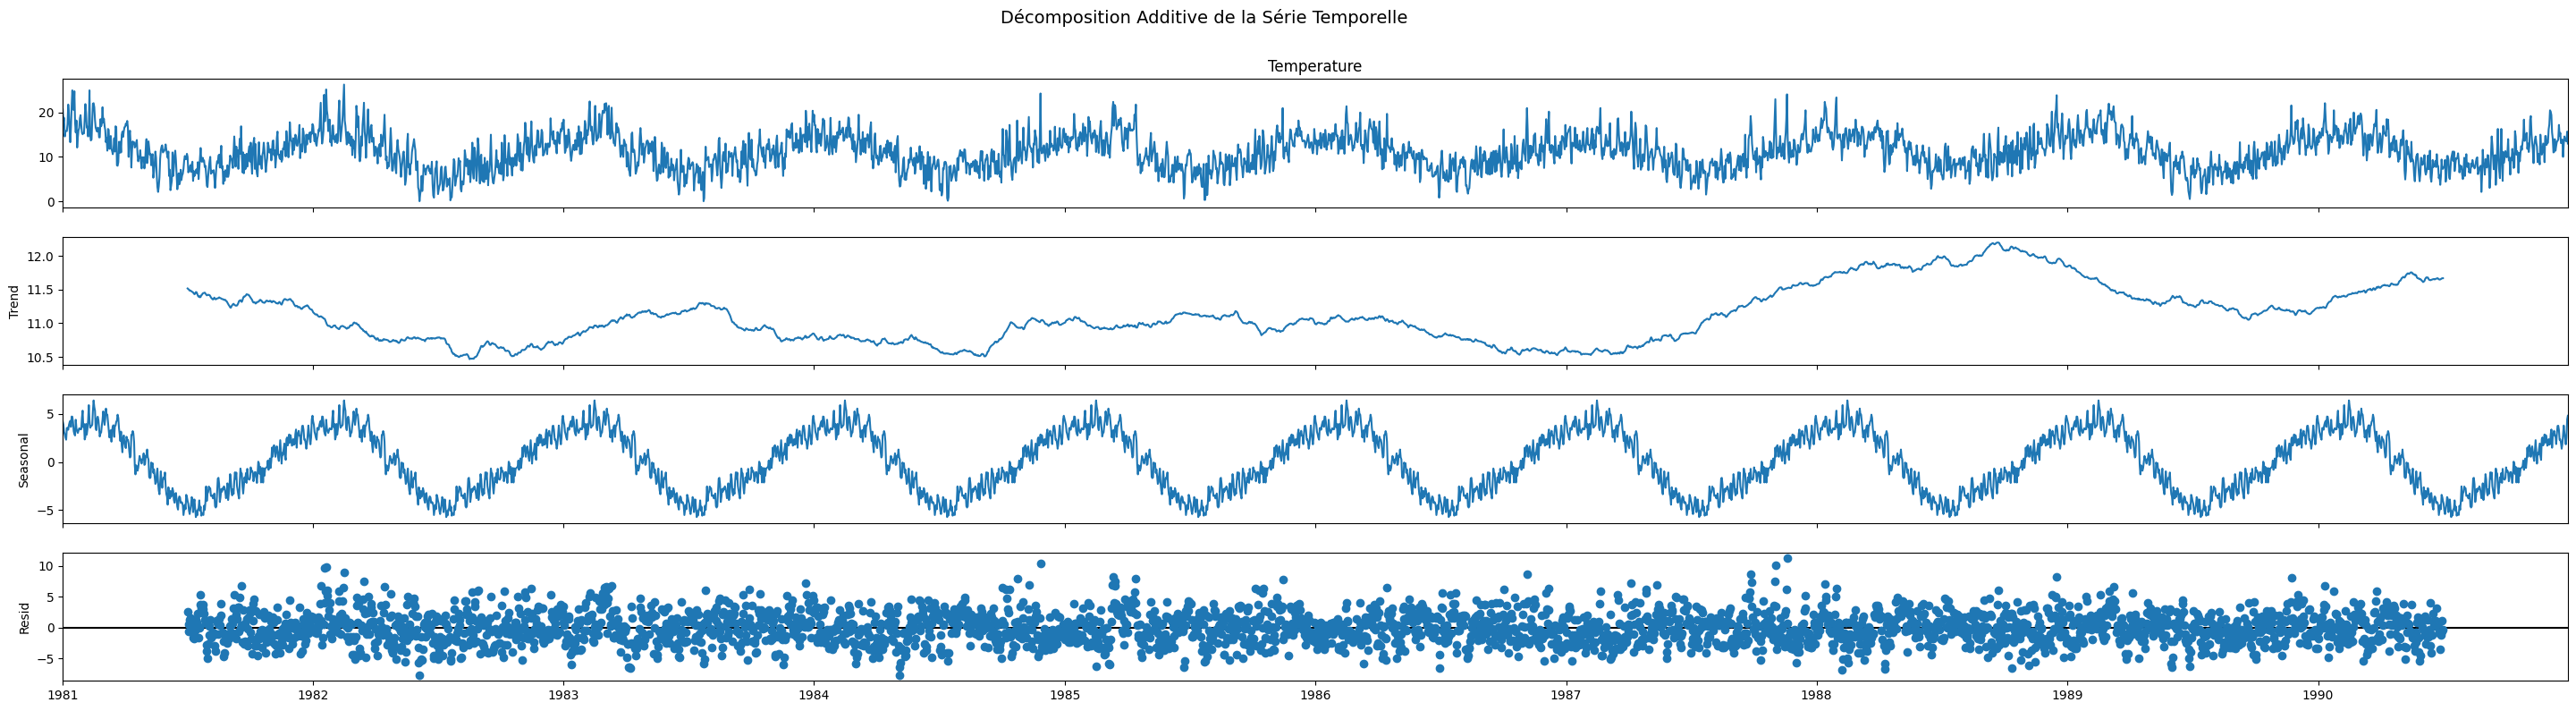

In [187]:
# check trend, seasonality, and white noise
# Décomposition de la série temporelle

from statsmodels.tsa.seasonal import seasonal_decompose

decomposition = seasonal_decompose(df["Temperature"], model= "additive", period= 365 ) # jeu de données journalier (1 point par 1 jour) le cycle sur une année

fig = decomposition.plot()
fig.set_size_inches(32, 8)
plt.suptitle("Décomposition Additive de la Série Temporelle", fontsize=14, y=1.02)
plt.show()


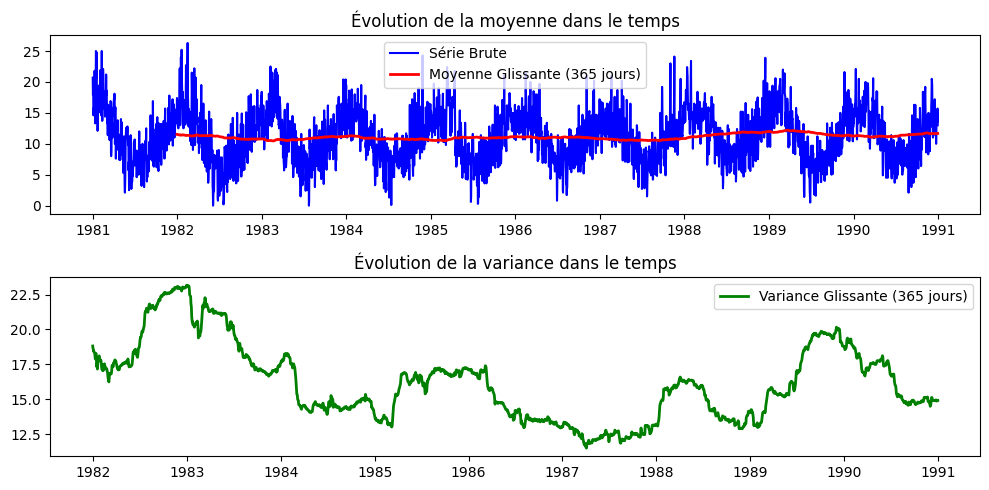

In [188]:
# Vérifier la stationarité de la série temporelle

window_size = 365

rolling_mean= df["Temperature"].rolling(window= window_size).mean()
rolling_variance = df["Temperature"].rolling(window= window_size).var()

# Visualisation pour vérifer si la moyenne et la variance sont constantes

plt.figure(figsize=(10,5))
plt.subplot(2, 1, 1)
plt.plot(df['Temperature'], label='Série Brute', color='blue')
plt.plot(rolling_mean, label='Moyenne Glissante (365 jours)', color='red', linewidth=2)
plt.legend()
plt.title("Évolution de la moyenne dans le temps")

plt.subplot(2, 1, 2)
plt.plot(rolling_variance, label='Variance Glissante (365 jours)', color='green', linewidth=2)
plt.legend()
plt.title("Évolution de la variance dans le temps")

plt.tight_layout()
plt.show()

In [189]:
# Vérifier la stationarité de la série avec les testes statistiques

# Test ADF

from statsmodels.tsa.stattools import adfuller

result_brut = adfuller(df["Temperature"])

p_value = result_brut[1]


print(f"p_value = {p_value:.2f}\n")

if p_value> 0.05:
    print("La série est NON stationnaire.")
if p_value < 0.05:
    print("La série est stationnaire.")


p_value = 0.00

La série est stationnaire.


/tmp/ipykernel_8451/3832957267.py:7: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  result_brut = adfuller(df["Temperature"])


<b>La série est stationnaire, donc on peut directement appliquer les modèles ARIMA sans passer par la différenciation ou la transformation Box Cox.

In [190]:
# Divisier les données en train et test
train = df["Temperature"][:3285]  # 9 ans du 01-01-1981 à 31-12-1989
test = df["Temperature"][3285:]  # 1 ans du 01-01-1990 à 31-12-1990

In [191]:
len(train), len(test)

(3285, 365)

### 1. Lissage exponentielle

In [192]:
# Modèle Lissage exponentielle
from statsmodels.tsa.holtwinters import ExponentialSmoothing

model_lissage_expo = ExponentialSmoothing(
                            train.to_numpy(),
                            trend= 'add', # additive
                            seasonal= 'add',
                            seasonal_periods= 365
                            ).fit()

model_lissage_expo.params_formatted

/usr/local/lib/python3.13/dist-packages/statsmodels/tsa/holtwinters/model.py:1065: ConvergenceWarning: Optimization failed to converge. Check mle_retvals.
  res = self._optimize_parameters(res, use_brute, method, minimize_kwargs)


,name,param,optimized
smoothing_level,alpha,0.430762,True
smoothing_trend,beta,0.000000,True
smoothing_seasonal,gamma,0.000000,True
initial_level,l.0,11.997876,True
initial_trend,b.0,-0.001251,True
...,...,...,...
initial_seasons.360,s.360,3.131402,True
initial_seasons.361,s.361,2.734521,True
initial_seasons.362,s.362,3.485384,True
initial_seasons.363,s.363,5.447476,True


In [193]:
# Faire des prédictions
predictions_lissage_expo = pd.Series(
    model_lissage_expo.forecast(len(test)),
    index=test.index
)



In [194]:
predictions_lissage_expo

,0
Date,
1990-01-01,13.154894
1990-01-02,12.568576
1990-01-03,11.479167
1990-01-04,10.658086
1990-01-05,10.285713
...,...
1990-12-27,10.604708
1990-12-28,10.206576
1990-12-29,10.956187


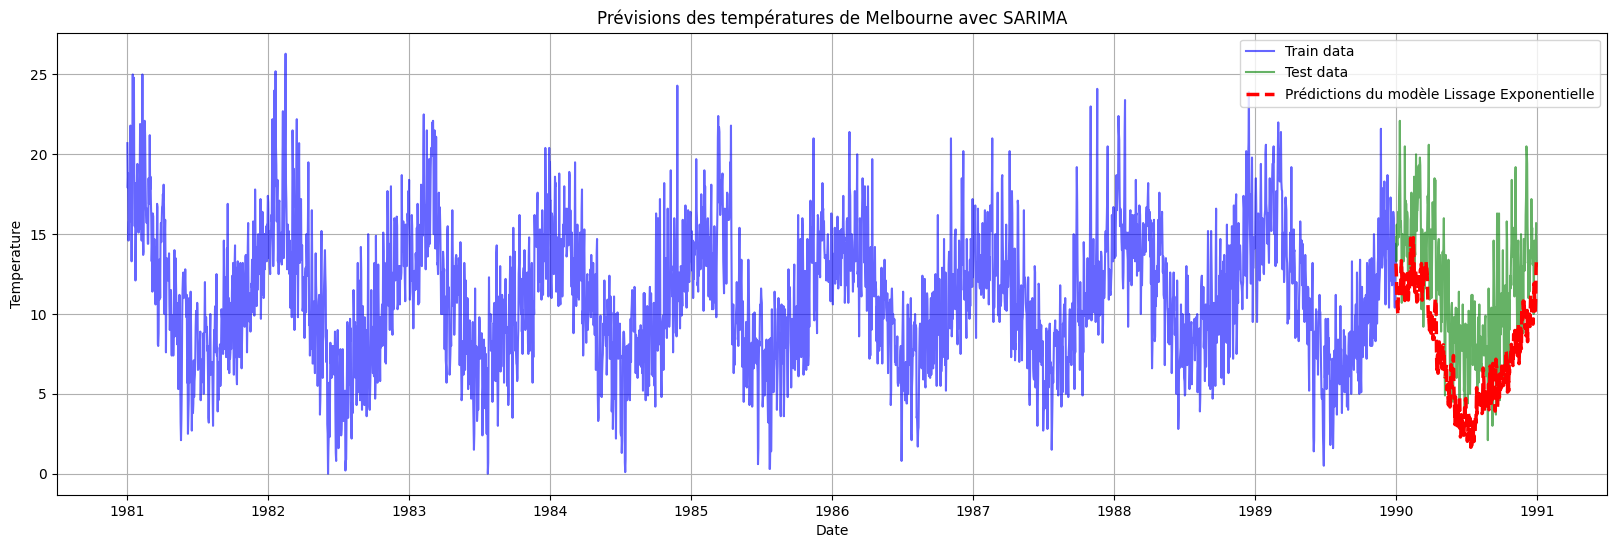

In [ ]:
plt.figure(figsize=(20, 6))

plt.plot(train, label= "Train data", color= "blue", alpha= 0.6)
plt.plot(test, label = "Test data", color= "green", alpha= 0.6)
plt.plot(predictions_lissage_expo, label="Prédictions du modèle Lissage Exponentielle", color= "red", linestyle= "--", linewidth= 2.5)

plt.xlabel("Date")
plt.ylabel("Temperature")
plt.title("Prévisions des températures de Melbourne avec Holt Winters")
plt.legend()
plt.grid(True)
plt.show()

In [196]:
from sklearn.metrics import mean_absolute_error, mean_squared_error

mae = mean_absolute_error(y_true= test, y_pred= predictions_lissage_expo)
mse = mean_squared_error(y_true= test, y_pred= predictions_lissage_expo)

print(f"MAE = {mae:.2f}")
print(f"MSE = {mse:.2f}")


MAE = 4.17
MSE = 23.47


### 2. Machine learning

In [197]:
df_ml.head()

,Temperature
Date,
1981-01-01,20.7
1981-01-02,17.9
1981-01-03,18.8
1981-01-04,14.6
1981-01-05,15.8


In [198]:
# Création des varaibles calendriers 

df_ml["month"] = df_ml.index.month
df_ml["dayofweek"] = df_ml.index.dayofweek
df_ml["dayofmonth"] = df_ml.index.day

df_ml.head()


,Temperature,month,dayofweek,dayofmonth
Date,,,,
1981-01-01,20.7,1,3,1
1981-01-02,17.9,1,4,2
1981-01-03,18.8,1,5,3
1981-01-04,14.6,1,6,4
1981-01-05,15.8,1,0,5


In [199]:
# Variables de retards 
df_ml["lag_1"] = df["Temperature"].shift(1)
df_ml["lag_7"] = df["Temperature"].shift(7)
df_ml["lag_365"] = df["Temperature"].shift(365)

df_ml.head()

,Temperature,month,dayofweek,dayofmonth,lag_1,lag_7,lag_365
Date,,,,,,,
1981-01-01,20.7,1,3,1,NaN,NaN,NaN
1981-01-02,17.9,1,4,2,20.7,NaN,NaN
1981-01-03,18.8,1,5,3,17.9,NaN,NaN
1981-01-04,14.6,1,6,4,18.8,NaN,NaN
1981-01-05,15.8,1,0,5,14.6,NaN,NaN


In [200]:
df_ml.isnull().sum()

,0
Temperature,0
month,0
dayofweek,0
dayofmonth,0
lag_1,1
lag_7,7
lag_365,365


In [201]:
df_ml = df_ml.dropna()

In [202]:
df_ml.isnull().sum()

,0
Temperature,0
month,0
dayofweek,0
dayofmonth,0
lag_1,0
lag_7,0
lag_365,0


In [203]:
df_ml.shape

(3285, 7)

In [204]:
# séparation en train et test
train_ml = df_ml.loc[:'1989-12-31'] # 9 ans du 01-01-1981 à 31-12-1989

test_ml = df_ml.loc['1990-01-01':]  # 1 ans du 01-01-1990 à 31-12-1990

In [205]:
print(len(train_ml), len(test_ml))

2920 365


In [206]:
# division des données en features et target

X_train = train_ml.drop(columns= ["Temperature"])
y_train = train_ml['Temperature']

X_test = test_ml.drop(columns= ['Temperature'])
y_test = test_ml['Temperature']

In [207]:
import lightgbm as lgb


In [208]:
model_lgb = lgb.LGBMRegressor(random_state= 42, n_estimators= 150)

model_lgb.fit(X_train, y_train)


[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.000351 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 627
[LightGBM] [Info] Number of data points in the train set: 2920, number of used features: 6
[LightGBM] [Info] Start training from score 11.073836


LGBMRegressor(n_estimators=150, random_state=42)

In [209]:
# Prédictions
predictions_lgb = model_lgb.predict(X_test)
predictions_lgb = pd.Series(predictions_lgb, index= y_test.index)

predictions_lgb

,0
Date,
1990-01-01,13.290561
1990-01-02,13.437438
1990-01-03,14.108763
1990-01-04,14.178098
1990-01-05,13.302683
...,...
1990-12-27,14.865133
1990-12-28,14.178411
1990-12-29,15.219633


In [210]:
mae = mean_absolute_error(y_true= y_test, y_pred= predictions_lgb)
mse = mean_squared_error(y_true= y_test, y_pred= predictions_lgb)

print(f"MAE = {mae:.2f}")
print(f"MSE = {mse:.2f}")

MAE = 1.87
MSE = 5.65


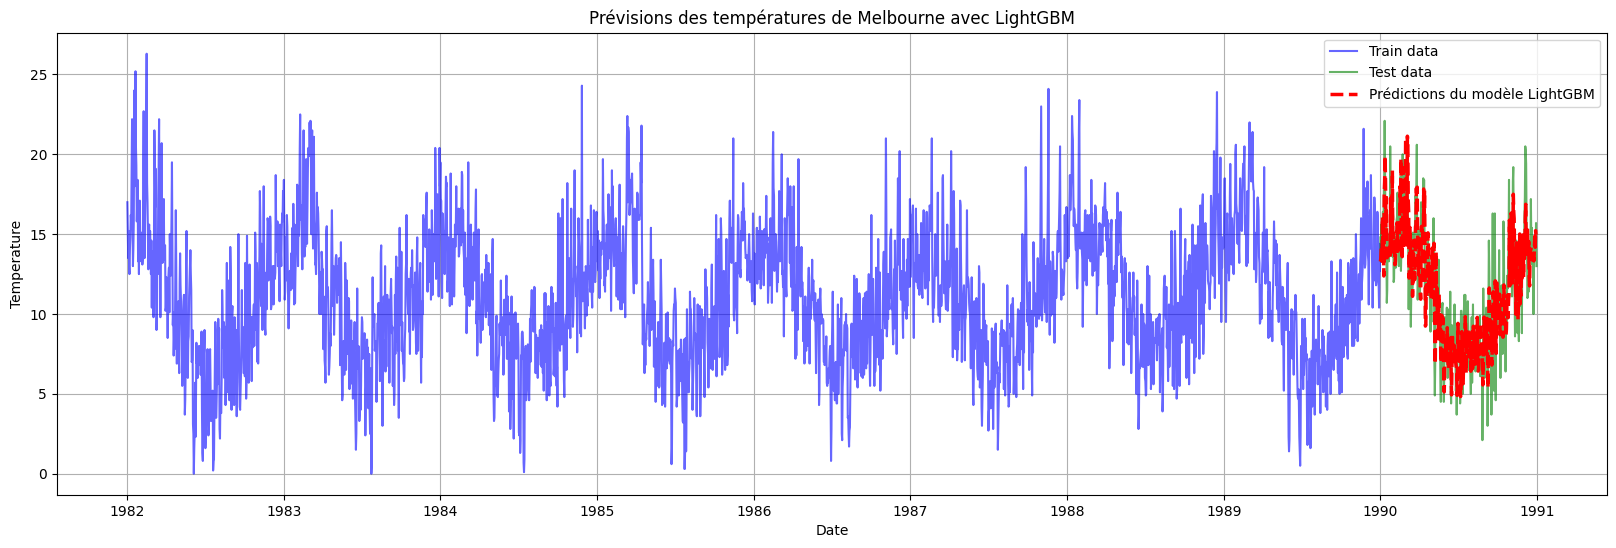

In [212]:
plt.figure(figsize=(20, 6))

plt.plot(y_train, label= "Train data", color= "blue", alpha= 0.6)
plt.plot(y_test, label = "Test data", color= "green", alpha= 0.6)
plt.plot(predictions_lgb, label="Prédictions du modèle LightGBM", color= "red", linestyle= "--", linewidth= 2.5)

plt.xlabel("Date")
plt.ylabel("Temperature")
plt.title("Prévisions des températures de Melbourne avec LightGBM")
plt.legend()
plt.grid(True)
plt.show()

<b>Donc le modèle LightGBM est plus performant que Holt Winters.</b>

- LightGBM:
    - MAE = 1.87
    - MSE = 5.65

- Holt Winters:
    - MAE = 4.17
    - MSE = 23.47
